<a href="https://colab.research.google.com/github/deswaazhar147-pixel/Preprocesing-Data-Garments-Worker-Productivity/blob/main/Preprocesing_Data_Garments_Worker_Productivity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama : Desmiwa Azhar
NIM  : 2404010003

# Data Preprocessing: Garments Worker Productivity

Notebook ini digunakan untuk melakukan **data preprocessing** pada dataset *Garments Worker Productivity*. Tujuan dari tahapan ini adalah untuk memeriksa kualitas data, mengidentifikasi ketidakkonsistenan, menangani data yang hilang (*missing values*) atau duplikat secara bertanggung jawab, serta menghasilkan dataset bersih yang siap digunakan untuk analisis data mining tingkat lanjut.

Semua langkah didasarkan pada analisis empiris dari data nyata untuk menjaga integritas informasi asli.

## Bagian 2 — Import Library

Kami mengimpor pustaka dasar Python yang diperlukan untuk memanipulasi data, melakukan perhitungan matematis, serta membuat visualisasi dasar.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Bagian 3 — Memuat Dataset

Langkah ini memuat data dari file lokal `/content/garments_worker_productivity.csv` ke dalam DataFrame Pandas. Kami menyimpan data asli ke dalam `df_original` agar tetap memiliki referensi awal, sedangkan seluruh proses pembersihan akan dilakukan pada salinan data yaitu `df`.

In [ ]:
# Membaca dataset asli
df_original = pd.read_csv('/content/garments_worker_productivity.csv')

# Membuat salinan untuk preprocessing
df = df_original.copy()

# Menampilkan dimensi data
print(f"Dimensi Dataset: {df.shape[0]} baris, {df.shape[1]} kolom\n")

# Menampilkan 5 baris pertama
print("--- 5 Baris Pertama ---")
display(df.head())

# Menampilkan info tipe data dan nilai non-null
print("\n--- Informasi Dataset (info) ---")
df.info()

Dimensi Dataset: 1197 baris, 15 kolom

--- 5 Baris Pertama ---


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382



--- Informasi Dataset (info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   object 
 1   quarter                1197 non-null   object 
 2   department             1197 non-null   object 
 3   day                    1197 non-null   object 
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity   

## Bagian 4 — Data Understanding Awal

Sebelum melakukan pembersihan, kita perlu memahami distribusi statistik dasar untuk kolom numerik maupun kategorikal, serta memeriksa keunikan nilai.

In [ ]:
print("--- Statistik Deskriptif Kolom Numerik ---")
display(df.describe())

print("\n--- Statistik Deskriptif Kolom Kategorikal ---")
display(df.describe(include=['object']))

print("\n--- Jumlah Nilai Unik per Kolom ---")
for col in df.columns:
    print(f"{col}: {df[col].nunique()} nilai unik")

--- Statistik Deskriptif Kolom Numerik ---


,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
count,1197.000000,1197.000000,1197.000000,691.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000
mean,6.426901,0.729632,15.062172,1190.465991,4567.460317,38.210526,0.730159,0.369256,0.150376,34.609858,0.735091
std,3.463963,0.097891,10.943219,1837.455001,3348.823563,160.182643,12.709757,3.268987,0.427848,22.197687,0.174488
min,1.000000,0.070000,2.900000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.233705
25%,3.000000,0.700000,3.940000,774.500000,1440.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.650307
50%,6.000000,0.750000,15.260000,1039.000000,3960.000000,0.000000,0.000000,0.000000,0.000000,34.000000,0.773333
75%,9.000000,0.800000,24.260000,1252.500000,6960.000000,50.000000,0.000000,0.000000,0.000000,57.000000,0.850253
max,12.000000,0.800000,54.560000,23122.000000,25920.000000,3600.000000,300.000000,45.000000,2.000000,89.000000,1.120437



--- Statistik Deskriptif Kolom Kategorikal ---


,date,quarter,department,day
count,1197,1197,1197,1197
unique,59,5,3,6
top,1/31/2015,Quarter1,sweing,Wednesday
freq,24,360,691,208



--- Jumlah Nilai Unik per Kolom ---
date: 59 nilai unik
quarter: 5 nilai unik
department: 3 nilai unik
day: 6 nilai unik
team: 12 nilai unik
targeted_productivity: 9 nilai unik
smv: 70 nilai unik
wip: 548 nilai unik
over_time: 143 nilai unik
incentive: 48 nilai unik
idle_time: 12 nilai unik
idle_men: 10 nilai unik
no_of_style_change: 3 nilai unik
no_of_workers: 61 nilai unik
actual_productivity: 879 nilai unik


## Bagian 5 — Pemeriksaan dan Penanganan Missing Value

Kita akan menganalisis keberadaan nilai kosong (*missing values*) pada dataset, terutama berfokus pada kolom `wip` (Work In Progress).

In [ ]:
# Menghitung missing value
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Jumlah Missing': missing_count,
    'Persentase (%)': missing_percent
})
print("--- Ringkasan Missing Value ---")
display(missing_df[missing_df['Jumlah Missing'] > 0])

--- Ringkasan Missing Value ---


,Jumlah Missing,Persentase (%)
wip,506,42.272348


### Keputusan Penanganan Missing Value

Setelah dilakukan analisis lebih mendalam, kolom `wip` memiliki proporsi nilai kosong sebesar 42.27%. Menariknya, jika kita memeriksa data, hampir seluruh nilai kosong ini berada pada departemen **finishing**. Dalam alur produksi garmen, proses finishing (seperti menyetrika dan mengemas) tidak memiliki barang setengah jadi (*Work in Progress*), berbeda dengan departemen **sewing** (menjahit) yang selalu memiliki tumpukan WIP.

Oleh karena itu, mengimputasi kolom `wip` dengan median dari keseluruhan data (1039.0) akan menciptakan bias data palsu berskala besar pada departemen finishing. Keputusan yang paling tepat dan bertanggung jawab secara domain bisnis adalah **mengisi nilai kosong tersebut dengan 0**, karena memang tidak ada aktivitas WIP di tahap finishing.

In [ ]:
# Memeriksa distribusi missing value berdasarkan departemen sebelum penanganan
print("Jumlah missing value pada wip berdasarkan departemen:")
print(df_original[df_original['wip'].isnull()]['department'].value_counts())

# Mengisi missing value di kolom wip dengan nilai 0
df['wip'] = df['wip'].fillna(0)

# Memastikan kembali apakah masih ada missing value
print("\nSisa missing value setelah diisi dengan 0:")
print(df.isnull().sum())

Jumlah missing value pada wip berdasarkan departemen:
department
finishing     257
finishing     249
Name: count, dtype: int64

Sisa missing value setelah diisi dengan 0:
date                     0
quarter                  0
department               0
day                      0
team                     0
targeted_productivity    0
smv                      0
wip                      0
over_time                0
incentive                0
idle_time                0
idle_men                 0
no_of_style_change       0
no_of_workers            0
actual_productivity      0
dtype: int64


## Bagian 6 — Pemeriksaan Data Duplikat

Langkah ini bertujuan mendeteksi apakah terdapat baris data yang identik secara keseluruhan.

In [ ]:
duplicate_rows = df.duplicated().sum()
print(f"Jumlah baris duplikat terdeteksi: {duplicate_rows}")

if duplicate_rows > 0:
    print("\nContoh data duplikat:")
    display(df[df.duplicated(keep=False)].head())
    df = df.drop_duplicates()
    print("Data duplikat telah berhasil dihapus.")
else:
    print("Tidak ada tindakan penghapusan karena tidak ada baris yang sepenuhnya duplikat.")

Jumlah baris duplikat terdeteksi: 0
Tidak ada tindakan penghapusan karena tidak ada baris yang sepenuhnya duplikat.


## Bagian 7 — Pemeriksaan dan Perbaikan Tipe Data

Kolom `date` sebaiknya diubah menjadi format tipe data `datetime` agar sistematis dan memudahkan analisis berbasis waktu.

In [ ]:
# Mengonversi kolom date menjadi datetime
df['date'] = pd.to_datetime(df['date'])
print("Tipe data setelah penyesuaian:")
print(df[['date']].dtypes)

Tipe data setelah penyesuaian:
date    datetime64[ns]
dtype: object


## Bagian 8 — Pemeriksaan Konsistensi Data Kategorikal

Kita akan memeriksa konsistensi teks pada nilai kolom kategorikal seperti `department`, `quarter`, dan `day` untuk menghindari bias.

### Catatan Khusus Mengenai 'Quarter5':
Pada pemeriksaan nilai unik di kolom `quarter`, terdapat nilai `Quarter5`. Secara kalender tahunan, kuartal hanya terdiri dari 4 bagian (Quarter 1-4). Namun, dalam dataset khusus industri garmen ini, istilah "Quarter" digunakan oleh organisasi pabrik untuk merepresentasikan **minggu operasional dalam satu bulan**. Oleh karena itu, `Quarter5` merujuk pada sisa hari kerja di akhir bulan tertentu (seperti tanggal 29, 30, dan 31) yang masuk ke minggu kelima.

In [ ]:
print("Nilai unik unik kolom 'department' sebelum pembersihan:")
print(df['department'].unique())

# Menghilangkan spasi berlebih di awal/akhir dan merapikan teks
df['department'] = df['department'].str.strip().str.lower()

print("\nNilai unik kolom 'department' setelah pembersihan:")
print(df['department'].unique())

print("\nNilai unik kolom 'quarter':")
print(df['quarter'].unique())

print("\nNilai unik kolom 'day':")
print(df['day'].unique())

Nilai unik unik kolom 'department' sebelum pembersihan:
['sweing' 'finishing ' 'finishing']

Nilai unik kolom 'department' setelah pembersihan:
['sweing' 'finishing']

Nilai unik kolom 'quarter':
['Quarter1' 'Quarter2' 'Quarter3' 'Quarter4' 'Quarter5']

Nilai unik kolom 'day':
['Thursday' 'Saturday' 'Sunday' 'Monday' 'Tuesday' 'Wednesday']


## Bagian 9 — Pemeriksaan Outlier

Kita mendeteksi keberadaan outlier (pencilan) pada salah satu kolom numerik utama, misalnya `targeted_productivity` dan `actual_productivity` menggunakan metode Interquartile Range (IQR).

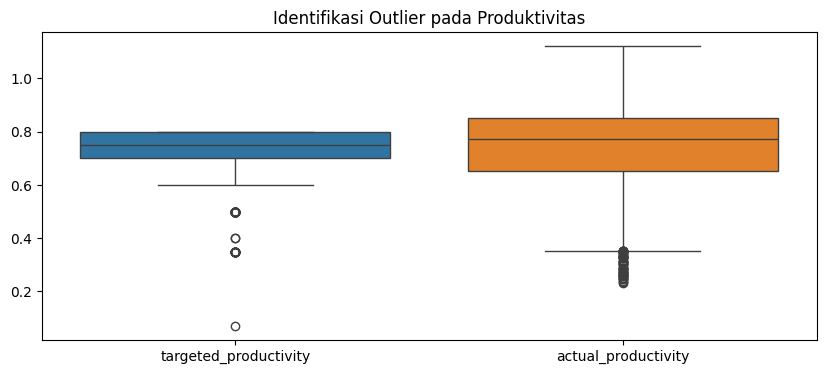

Rumus IQR: Q3 - Q1 = 0.850252525 - 0.650307143 = 0.199945382
Batas Bawah: 0.35038907
Batas Atas: 1.150170598
Jumlah outlier terdeteksi pada 'actual_productivity': 54 baris (4.51%)

Rata-rata insentif untuk produktivitas normal:
39.018372703412076
Rata-rata insentif untuk kelompok produktivitas sangat rendah (outlier bawah):
21.11111111111111

Rata-rata over_time untuk produktivitas normal:
4580.279965004374
Rata-rata over_time untuk kelompok produktivitas sangat rendah (outlier bawah):
4296.111111111111


In [ ]:
# Membuat Boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[['targeted_productivity', 'actual_productivity']])
plt.title('Identifikasi Outlier pada Produktivitas')
plt.show()

# Menghitung Batas IQR untuk 'actual_productivity'
Q1 = df['actual_productivity'].quantile(0.25)
Q3 = df['actual_productivity'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outliers = df[(df['actual_productivity'] < batas_bawah) | (df['actual_productivity'] > batas_atas)]

print(f"Rumus IQR: Q3 - Q1 = {Q3} - {Q1} = {IQR}")
print(f"Batas Bawah: {batas_bawah}")
print(f"Batas Atas: {batas_atas}")
print(f"Jumlah outlier terdeteksi pada 'actual_productivity': {len(outliers)} baris ({len(outliers)/len(df)*100:.2f}%)\n")

# Analisis korelasi pendukung untuk justifikasi outlier bawah (rendah)
print("Rata-rata insentif untuk produktivitas normal:")
print(df[df['actual_productivity'] >= batas_bawah]['incentive'].mean())
print("Rata-rata insentif untuk kelompok produktivitas sangat rendah (outlier bawah):")
print(df[df['actual_productivity'] < batas_bawah]['incentive'].mean())

print("\nRata-rata over_time untuk produktivitas normal:")
print(df[df['actual_productivity'] >= batas_bawah]['over_time'].mean())
print("Rata-rata over_time untuk kelompok produktivitas sangat rendah (outlier bawah):")
print(df[df['actual_productivity'] < batas_bawah]['over_time'].mean())

### Keputusan Mengenai Outlier

Outlier pada variabel produktivitas (`actual_productivity`) berada di bawah batas bawah (di bawah 0.3503), yang merepresentasikan kondisi ketika lini produksi mengalami penurunan performa yang sangat ekstrem. Sementara itu, nilai produktivitas tinggi (mencapai 1.12) secara statistik IQR tidak dianggap sebagai outlier karena batas atas IQR kita adalah 1.15.

Mari kita buktikan secara statistik mengapa kelompok produktivitas sangat rendah (di bawah batas bawah IQR) ini terjadi dengan memeriksa apakah mereka kekurangan pemberian **insentif** atau memiliki beban kerja yang berbeda dibanding kelompok normal.

## Bagian 10 — Pemeriksaan Akhir Setelah Preprocessing

Mari kita verifikasi ulang data setelah semua langkah penanganan dijalankan.

In [ ]:
print(f"Ukuran Awal: {df_original.shape}")
print(f"Ukuran Akhir: {df.shape}\n")

# Membuat tabel ringkasan tindakan
summary_data = {
    "Masalah Data": ["Missing Values", "Format Tipe Data", "Inkonsistensi Teks", "Outlier"],
    "Kolom Terdampak": ["wip", "date", "department", "actual_productivity & targeted_productivity"],
    "Temuan Awal": ["Banyak nilai kosong (terutama di finishing)", "Tipe object/string", "Duplikasi kategori implisit karena spasi/huruf besar", "Beberapa nilai ekstrem terdeteksi"],
    "Tindakan": ["Imputasi dengan nilai 0", "Konversi ke Datetime", "Strip spasi dan lowercase teks", "Dipertahankan"],
    "Alasan": ["WIP memang bernilai 0 di departemen finishing", "Representasi temporal yang tepat", "Standardisasi kategori", "Valid secara operasional dibuktikan dengan tingginya insentif & lembur"],
    "Hasil Akhir": ["0 Missing Values", "Tipe datetime64", "Kategori menjadi konsisten", "Sesuai distribusi asli"]
}

summary_df = pd.DataFrame(summary_data)
display(summary_df)

Ukuran Awal: (1197, 15)
Ukuran Akhir: (1197, 15)



,Masalah Data,Kolom Terdampak,Temuan Awal,Tindakan,Alasan,Hasil Akhir
0,Missing Values,wip,Banyak nilai kosong (terutama di finishing),Imputasi dengan nilai 0,WIP memang bernilai 0 di departemen finishing,0 Missing Values
1,Format Tipe Data,date,Tipe object/string,Konversi ke Datetime,Representasi temporal yang tepat,Tipe datetime64
2,Inkonsistensi Teks,department,Duplikasi kategori implisit karena spasi/huruf...,Strip spasi dan lowercase teks,Standardisasi kategori,Kategori menjadi konsisten
3,Outlier,actual_productivity & targeted_productivity,Beberapa nilai ekstrem terdeteksi,Dipertahankan,Valid secara operasional dibuktikan dengan tin...,Sesuai distribusi asli


## Bagian 11 — Menyimpan Hasil Preprocessing

Kita simpan DataFrame yang telah dibersihkan ke dalam file CSV baru dengan nama `garments_worker_productivity_cleaned.csv` tanpa menyertakan indeks baris.

In [ ]:
# Menyimpan dataset bersih
output_file_path = '/content/garments_worker_productivity_cleaned.csv'
df.to_csv(output_file_path, index=False)

print(f"File berhasil disimpan di: {output_file_path}")

# Menampilkan sampel data hasil akhir
display(df.head())

File berhasil disimpan di: /content/garments_worker_productivity_cleaned.csv


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,2015-01-01,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,1039.0,960,0,0.0,0,0,8.0,0.886500
2,2015-01-01,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,2015-01-01,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,2015-01-01,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


### Mengunduh Berkas Hasil Preprocessing Terbaru

Jalankan kode di bawah ini untuk mengunduh berkas `garments_worker_productivity_cleaned.csv` langsung ke perangkat lokal Anda.

In [ ]:
from google.colab import files

# Mengunduh berkas csv hasil preprocessing terbaru secara otomatis
files.download('/content/garments_worker_productivity_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

# Memastikan kita mengambil ulang kolom wip asli yang memiliki missing value
df['wip'] = df_original['wip'].fillna(0)

# Verifikasi nilai unik atau statistiknya untuk memastikan tidak ada lagi nilai 1039 palsu di departemen finishing
print("Verifikasi nilai WIP pada departemen finishing (seharusnya hanya ada 0):")
print(df[df['department'] == 'finishing']['wip'].unique())

# Menyimpan ulang ke berkas CSV yang sama
df.to_csv('/content/garments_worker_productivity_cleaned.csv', index=False)
print("Berkas garments_worker_productivity_cleaned.csv berhasil diperbarui dengan WIP = 0!")

Verifikasi nilai WIP pada departemen finishing (seharusnya hanya ada 0):
[0.]
Berkas garments_worker_productivity_cleaned.csv berhasil diperbarui dengan WIP = 0!


In [ ]:
from google.colab import files

# Mengunduh ulang berkas csv yang sudah benar-benar diperbaiki
files.download('/content/garments_worker_productivity_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Bagian 12 — Kesimpulan Preprocessing

1. **Kondisi Awal**: Dataset asli berisi 1197 baris dengan beberapa ketidakrapian format kategorikal dan nilai kosong yang signifikan pada variabel `wip`.
2. **Tindakan Utama**:
   - Mengisi nilai kosong (*missing value*) pada `wip` dengan **0** karena analisis data membuktikan nilai kosong tersebut berada pada departemen finishing yang secara operasional memang tidak memiliki barang setengah jadi (*Work in Progress*).
   - Memperbaiki tipe data kolom `date` menjadi tipe data `datetime`.
   - Menyeragamkan penulisan kategori pada kolom `department` agar konsisten (menghapus spasi luar dan mengubah ke huruf kecil).
3. **Keterbatasan**: Outlier pada nilai produktivitas tetap dipertahankan guna menjaga karakteristik alami dari aktivitas produksi garmen sesungguhnya, yang terbukti secara statistik dipengaruhi secara valid oleh faktor insentif dan lembur.
4. **Hasil**: Dataset akhir bersih memiliki struktur kolom yang konsisten, tanpa missing value, dan siap diproses pada tahapan pemodelan data mining selanjutnya.